## Traditional methods

## Data Loading and explore

In [1]:
import pandas as pd

data = pd.read_csv('email.csv')
df = pd.DataFrame(data)

df.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [2]:
print(df.shape)
print(df.info())
print("Null: ",df.isnull().sum())
print("Duplicates: ",df.duplicated().sum())

(5573, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5573 entries, 0 to 5572
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5573 non-null   object
 1   Message   5573 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None
Null:  Category    0
Message     0
dtype: int64
Duplicates:  415


### Data preprocessing

In [3]:
df.drop_duplicates(inplace=True)
print(df.shape)

(5158, 2)


In [4]:
print(df["Category"].value_counts(normalize=True) * 100)

Category
ham               87.553315
spam              12.427297
{"mode":"full"     0.019387
Name: proportion, dtype: float64


In [5]:
df['Message'] = df['Message'].astype(str).str.strip().str.lower()
df = df[df['Message'] != '']
print(df.shape)
df.head()

(5158, 2)


,Category,Message
0,ham,"go until jurong point, crazy.. available only ..."
1,ham,ok lar... joking wif u oni...
2,spam,free entry in 2 a wkly comp to win fa cup fina...
3,ham,u dun say so early hor... u c already then say...
4,ham,"nah i don't think he goes to usf, he lives aro..."


In [6]:
df['Category'] = df['Category'].map({'spam':1,'ham':0})  
df.head()

,Category,Message
0,0.0,"go until jurong point, crazy.. available only ..."
1,0.0,ok lar... joking wif u oni...
2,1.0,free entry in 2 a wkly comp to win fa cup fina...
3,0.0,u dun say so early hor... u c already then say...
4,0.0,"nah i don't think he goes to usf, he lives aro..."


In [7]:
print(df['Category'].isnull().sum())
df.dropna(inplace=True)
df.head()

1


,Category,Message
0,0.0,"go until jurong point, crazy.. available only ..."
1,0.0,ok lar... joking wif u oni...
2,1.0,free entry in 2 a wkly comp to win fa cup fina...
3,0.0,u dun say so early hor... u c already then say...
4,0.0,"nah i don't think he goes to usf, he lives aro..."


### Train-test split

In [8]:
from sklearn.model_selection import train_test_split

X = df['Message']
y = df['Category']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4125
Testing samples: 1032


In [9]:
print((y_train.value_counts(normalize=True) * 100).round(2))
print((y_test.value_counts(normalize=True) * 100).round(2))


Category
0.0    87.56
1.0    12.44
Name: proportion, dtype: float64
Category
0.0    87.6
1.0    12.4
Name: proportion, dtype: float64


### TF-IDF Vectorization

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (4125, 5000)
Testing shape: (1032, 5000)


### Model training

In [63]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB()
}

predictions = {}
training_times = {}

for name, model in models.items():
    start = time.time()
    model.fit(X_train_tfidf, y_train)
    training_times[name] = time.time() - start

    predictions[name] = model.predict(X_test_tfidf)

    print(name, "trained successfully")

Logistic Regression trained successfully
Naive Bayes trained successfully


### Evaluation

In [65]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, pos_label=1),
        "Recall": recall_score(y_test, pred, pos_label=1),
        "F1-score": f1_score(y_test, pred, pos_label=1),
        "Training Time (s)": round(training_times[name], 2)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))

                 Model  Accuracy  Precision  Recall  F1-score  \
0  Logistic Regression    0.9632     0.9592  0.7344    0.8319   
1          Naive Bayes    0.9622     1.0000  0.6953    0.8203   

   Training Time (s)  
0               0.07  
1               0.01  


### Visualization

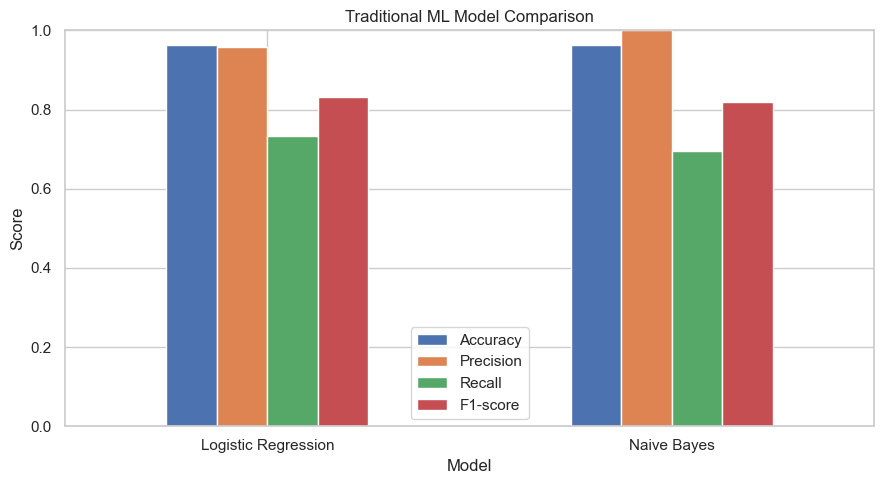

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(kind="bar", figsize=(9, 5))

plt.title("Traditional ML Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

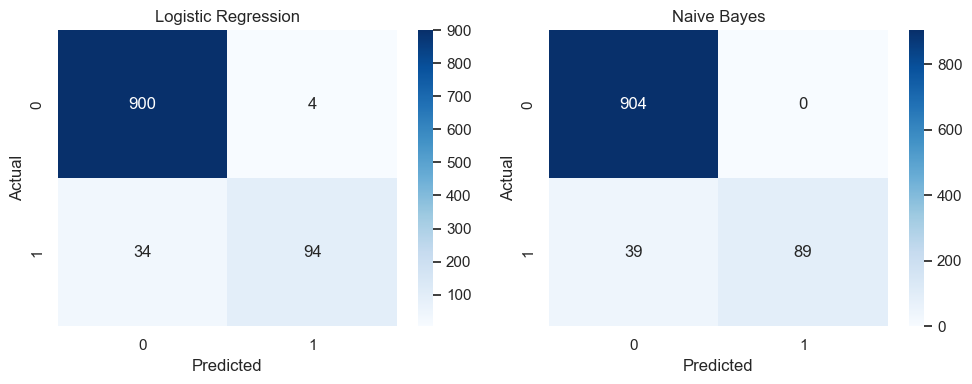

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred)

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()